# A história até aqui

Após a análise cuidadosa que efetuámos nos capítulos anteriores, temos agora uma boa compreensão das dificuldades associadas aos problemas discretos mal postos e de por que a **solução ingénua** pode ser **inútil**. Vimos que em problemas interessantes de escala média a grande, mesmo medições perfeitas podem falhar devido a erros de arredondamento. Podemos expressar a matriz de sensibilidade do problema em termos de sua decomposição em valores singulares (SVD), dada por

\begin{equation}
\textbf{A} = \textbf{U} \Sigma \textbf{V}^H=\sum\limits_{i=1}^{L}\textbf{u}_i \sigma_i \textbf{v}_{i}^{H},
\tag{1}
\end{equation}
em que as matrizes $\textbf{U} \in \mathbb{C}^{M \times L}$ e $\textbf{V} \in \mathbb{V}^{L \times L}$ são compostas por vetores coluna ortogonais chamados de left singular vectors ($\textbf{U} = [\textbf{u}_1, \textbf{u}_2, \cdots, \textbf{u}_M]$) e right singular vectors ($\textbf{V} = [\textbf{v}_1, \textbf{v}_2, \cdots, \textbf{v}_L]$). Já a matriz $\Sigma \in \mathbb{R}^{L \times L}$ é a matriz de valores singulares (**singular values**), que é diagonal com os valores singulares organizados em ordem **decrescente**, a saber

\begin{equation}
\Sigma = \text{diag}(\sigma_1, \sigma_2, ..., \sigma_L), \ \ \ \ \ \ \ \sigma_1 \geq \sigma_2 \geq \cdots \sigma_L.
\tag{2}
\end{equation}

Em geral, podemos dizer que o número de condição da matriz $\mathbf{A}$, dado por

\begin{equation}
\text{cond}(\mathbf{A}) = \sigma_1/\sigma_L,
\end{equation}
tende a crescer à medida que a ordem ($M, \ L$) do problema inverso aumenta.

### Os principais problemas são

A amplitude do fenômeno medido é menor (**e mais sujeita ao ruído**) para:
- maiores distâncias da fonte (decaimento natural do fenômeno com a distância);
- maiores frequências espaciais no fenômeno de origem, com as componentes de frequência espacial mais altas associadas aos menores valores singulares e, portanto, mais facilmente corrompidas pelo ruído.

# A necessidade de regularizar a solução

O alto número de condição e a presença de ruído implicam que a solução ingênua é muito sensível a qualquer perturbação do lado direito de $\mathbf{Ax} = \mathbf{b}$ (ruído nos dados medidos). Especificamente, suponha que as soluções **exatas** e **perturbadas** $\textbf{x}_{\text{exa}}$ e $\textbf{x}$ satisfazem

\begin{equation}
\textbf{A} \textbf{x}_{\text{exa}} = \textbf{b}_{\text{exa}} \ \ \ \ \& \ \ \ \ \textbf{A} \textbf{x} = \textbf{b} = \textbf{b}_{\text{exa}} + \textbf{n}
\end{equation}

Da teoria de perturbação temos os seguintes limites

\begin{equation}
\frac{\left\|\textbf{x}_{\text{exa}}-\textbf{x}\right\|_{2}}{\left\|\textbf{x}_{\text{exa}}\right\|_{2}} \leq \text{cond}(\textbf{A})\frac{\left\|\textbf{n}\right\|_{2}}{\left\|\textbf{b}_{\text{exa}}\right\|_{2}}
\tag{3}
\end{equation}
e já que $\text{cond}(\textbf{A})$ pode ser muito elevado, o lado esquerdo da Eq. (3) pode ser qualquer coisa. Isso implica que a diferença entre $\textbf{x}_{\text{exa}}$ e $\textbf{x}$ pode ser **arbitrariamente** grande se nada for feito.

Neste capítulo, usamos o conhecimento construído até aqui para conceber métodos diferentes para calcular **soluções sensatas** (aproximações) que são **menos sensíveis** a perturbações e ruído do que a solução ingénua.

Estes métodos são chamados **métodos de regularização** porque impõem regularidade à solução calculada — normalmente sob a forma de um requisito de que a **solução seja suave**, nalgum sentido. E ao impor esta regularidade, ou suavidade, suprimimos alguns dos componentes de ruído indesejados (a.k.a. componentes de alta frequência associados aos menores valores singulares), levando a soluções aproximadas mais estáveis. Quase todos os métodos de regularização abordados no capítulo produzem soluções que podem ser expressas como uma expansão de SVD. 

# Medição da densidade (toy problem)

Vamos relembrar rapidamente a medição inversa da densidade ao longo do espaço (1D), $\rho(x)$, que origina um campo gravitacional medido $g(x')$ a uma distância $d$ da fonte. Um esquema do problema pode ser visto na Figura 2. 

<figure style="text-align: center;">
    <img src="\..\figs\gravity.png" width="500" alt="Imagem do conceito do problema problema da gravidade.">
    <figcaption style="margin-top: 8px; font-style: italic; color: #555;">
        Figura 2: Conceito da medição inversa da densidade (Fonte: Discrete Inverse Problems Insight and Algorithms, Per Christian Hansen, SIAM, Fig. 2.1).
    </figcaption>
</figure>

A equação integral de Fredholm do problema em mãos é dada por

\begin{equation}
g(x') = \int_{0}^{1}K(x',x) \rho(x) \text{d}x
\end{equation}

com o Kernel (ou função de Green) dado por 

\begin{equation}
K(x',x) = \frac{d}{[d^2+(x' - x)^2]^{3/2}}.
\end{equation}

A dimensão física da densidade é $\rho(x)$ [kg/m] (1D). Falta a constante de gravitação universal, $G$ [Nm$^2$/kg$^2$], mas ela não fará muita falta pro nosso propósito.

## Quantificando a qualidade da solução

Vamos tentar quantificar o quão distante $\textbf{x}_{\text{exa}}$ e $\textbf{x}$ estão usando o Normalized Mean Square Error, dado por

\begin{equation}
\text{NMSE} = \frac{\left\|\textbf{x}_{\text{exa}}-\textbf{x}\right\|_2^2}{\left\|\textbf{x}_{\text{exa}}\right\|_2^2}
\tag{4}
\end{equation}
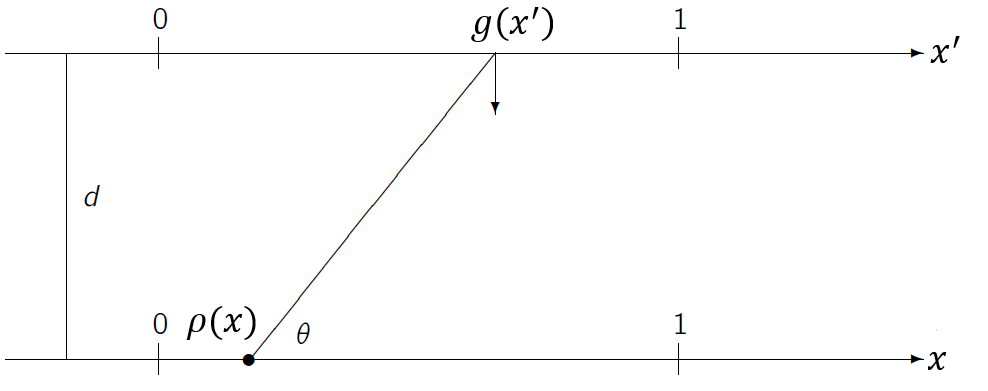

In [11]:
import numpy as np # arrays
import matplotlib.pyplot as plt # plots
import cvxpy as cp
import sys
sys.path.append('D:/Work/dev/insitu_sim_python/insitu')
import lcurve_functions as lc
sys.path.append("..")
import regu_test_problems as tp

In [12]:
# ordem
order = 64
# intervalo de medição
a = 0
b = 1
# distancia medida
d = 0.25
A, x = tp.gravity_model(n = order,a = a,b = b,d = d)
[U,s,V] = lc.csvd(A)
cond_A = s[0]/s[-1]
# source term
rhox = tp.density_sin(x, 0.5) + 0.5* tp.density_sin(x, 1.0)
# noiseless true solution (for reference)
gxl = A @ rhox
# Adding noise
n = np.random.normal(loc = 0.0, scale = 1, size = len(gxl))
n /= np.linalg.norm(n)
snr = -20
n *= (10**(snr/10))*np.linalg.norm(gxl)
print("computed SNR is {} [dB]".format(10*np.log10(np.linalg.norm(n)/np.linalg.norm(gxl))))
#n = np.random.normal(loc = 0.0, scale = 0.05, size = len(gxl))
gxln = gxl + n
# Naive solution via Inv
rhox_naive_inv = np.linalg.inv(A) @ gxln
nmse_inv = lc.nmse(x_sol = rhox_naive_inv, x_truth = rhox)
# Naive solution via SVD
rhox_naive_svd = (V @ np.diag(1/s) @ np.conj(U).T) @ gxln
nmse_svd = lc.nmse(x_sol = rhox_naive_svd, x_truth = rhox)

computed SNR is -20.0 [dB]


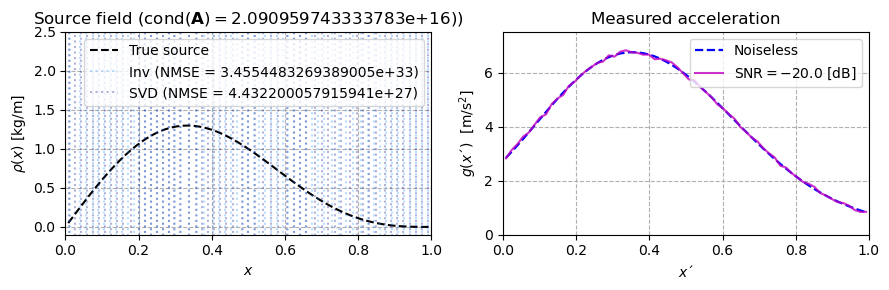

In [13]:
# Figure
fig, axs = plt.subplots(1, 2, figsize = (9,3))
axs[0].plot(x, rhox, '--k', label = "True source")
axs[0].plot(x, rhox_naive_inv, 'dodgerblue', linestyle = ':', label = "Inv (NMSE = {})".format(nmse_inv), alpha = 0.3)
axs[0].plot(x, rhox_naive_svd, 'navy', linestyle = ':', label = "SVD (NMSE = {})".format(nmse_svd), alpha = 0.3)
axs[0].legend()
axs[0].grid(linestyle = '--')
axs[0].set_xlim((0, 1))
axs[0].set_ylim((-0.1, 2.5))
axs[0].set_xlabel(r'$x$')
axs[0].set_ylabel(r'$\rho(x)$ [kg/m]')
axs[0].set_title(r'Source field (cond($\mathbf{{A}}) = ${}))'.format(cond_A))
axs[1].plot(x, gxl, label = r'Noiseless'.format(d), color = 'b', linestyle = '--', linewidth = 1.6)
axs[1].plot(x, gxln, label = r'SNR$ = {:.1f}$ [dB]'.format(snr), color = 'm', linestyle = '-', alpha = 0.8)
axs[1].grid(linestyle = '--')
axs[1].set_xlim((0, 1))
axs[1].set_ylim((0, 1.1*gxln.max()))
axs[1].legend(loc = 'upper right')
axs[1].grid(linestyle = '--')
axs[1].set_xlabel(r'$x´$')
axs[1].set_ylabel(r'$g(x´)$  [m/s$^2$]')
axs[1].set_title(r'Measured acceleration')
plt.tight_layout()

# Solução ingênua e SVD

Dado que $\textbf{A}^{-1} = \textbf{V} \Sigma^{-1} \textbf{U}^H$, podemos escrever a solução ingênua como

\begin{equation}
\textbf{x} = \textbf{A}^{-1}\textbf{b} = (\textbf{V} \Sigma^{-1} \textbf{U}^H) \textbf{b} =  \sum\limits_{i=1}^{L}\frac{\textbf{u}_{i}^{H}\textbf{b}}{\sigma_i} \textbf{v}_{i}
\tag{5}
\end{equation}

### Plots de Picard nas situações sem e com ruído

O **plot de Picard** nos ajudou na análise da saúde do problema inverso.

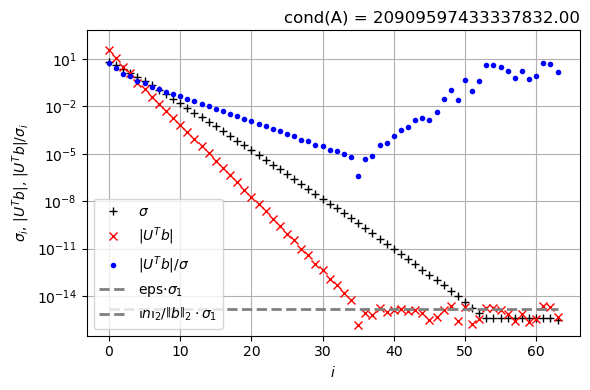

In [4]:
lc.plot_picard(U, s, gxl, noise_norm = 0, figsize = (6,4))

### A condição com ruído

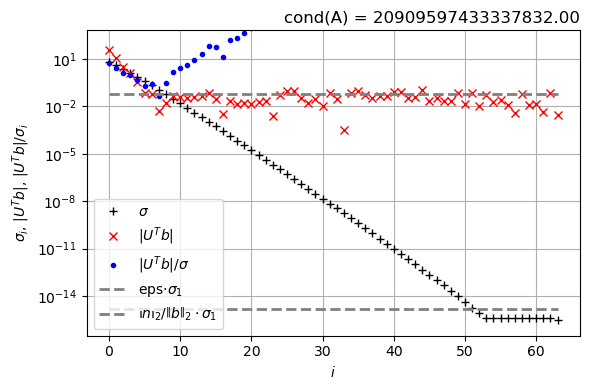

In [5]:
lc.plot_picard(U, s, gxln, noise_norm = np.linalg.norm(n), figsize = (6,4))

## A condição discreta de Picard

<div style="background-color: #f0f2f5; padding: 15px; text-align: justify; border-radius: 8px; margin: 0 auto; max-width: 1100px;">
Seja $\tau$ o $\textbf{nível}$ a partir do qual os valores singulares,  $\sigma_i$, computados tornam-se constantes devido a erros de arredondamento. A condição discreta de Picard é satisfeita se, para todos os valores singulares maiores do que $\tau$, os coeficientes correspondentes $|\textbf{u}_{i}^{T}b|$ decaem, em média, mais rapidamente do que os $\sigma_i$.
</div>

Nós sempre medimos $\textbf{b}$ com algum **ruído** ou **incerteza**, de modo que:

\begin{equation}
\textbf{b} =\textbf{b}_{\text{exact}} + \textbf{n}  
\end{equation}

Em resumo, existem dois tipos diferentes de coeficientes do lado direito de $\textbf{Ax} = \textbf{b}$:

- Há coeficientes confiáveis, caracterizados por $|\textbf{u}_{i}^{T}b| > \eta$, que contêm principalmente informação sobre os dados exatos, $\textbf{b}_{\text{exact}}$. Devido à condição discreta de Picard, estes coeficientes correspondem aos **maiores** valores singulares, $\sigma_i$.

- Existem componentes "ruidosos" do SVD, aqueles para os quais $|\textbf{u}_{i}^{T}\textbf{b}_{\text{exact}}| < \eta$ e para os quais $|\textbf{u}_{i}^{T}b| \approx \eta$. Estes coeficientes correspondem aos menores valores singulares, devido também à condição discreta de Picard.

### Lembre-se

Os **maiores** valores singulares estão associados às componentes de frequência mais elevadas, que decaem mais rapidamente e, portanto, são mais facilmente contaminadas por ruído.

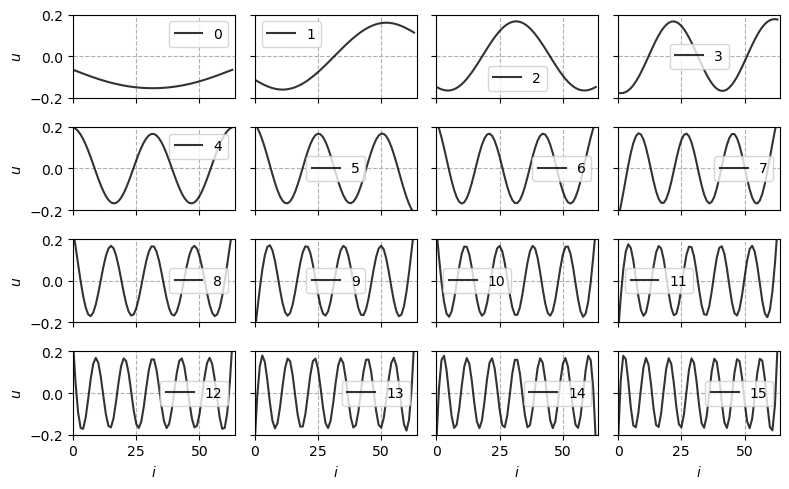

In [6]:
lc.plot_colvecs(U)

# 1. Forma geral da solução regularizada

Uma vez que computamos o SVD da matriz $\textbf{A}$ e entendemos o papel da **condição discreta de Picard**, podemos expressar a **solução sensata** da seguinte forma

\begin{equation}
\hat{\textbf{x}} = \sum\limits_{i=1}^{L}\varphi_i\frac{\textbf{u}_{i}^{H}\textbf{b}}{\sigma_i} \textbf{v}_{i},
\tag{6}
\end{equation}
em que $\varphi_i$ são **fatores de filtragem** (por ora genéricos) associados ao tipo de regularização a ser aplicada. Assim, esses métodos de regularização podem ser designados como métodos de **filtragem espectral** porque a ideia é domar a influência dos maiores valores singulares (associados aos componentes de maior frequência espacial). Em essência, a regularização de um problema inverso pode ser entendida como a aplicação de um filtro passa-baixas (o que talvez seja uma simplificação chocante demais pra ser levada 100% a sério).

# 2. Métodos de regularização e caminho de regularização

Investiguemos alguns métodos que podemos usar para regularizar nossa solução, a saber

- Otimização com restrição (*constrained optimization*)
- SVD truncado (*Truncated SVD* - TSVD)
- Regularização de Tikhonov

Existem muitos outros, mas vamos começar por aqui

## A. Otimização com restrição

Nos capítulos anteriores vimos uma forma de restringir a solução, dada por

\begin{equation}
\text{min}(\left\|\textbf{x}\right\|^{2}_{2}), \ \ \, \text{subjected to} \ \ \ \left\|\textbf{Ax -  b}\right\|^{2}_{2} \leq k \ \left\|\textbf{n}\right\|^{2}_{2}.
\tag{7}
\end{equation}

A ideia aqui é

- minimizar a norma da solução, $\mathbf{x}$,
- sujeito à condição de que a norma do resíduo, $\textbf{Ax -  b}$, seja menor ou igual ao produto de algum fator $k$ pela norma do ruído, $\textbf{n}$.

Vamos investigar como isso funciona. Para isso, precisamos assumir que "conhecemos" $\textbf{n}$ com algum grau de confiança.

Vamos investigar como o problema da gravidade se comporta sob diferentes escolhas de $k$. 

In [14]:
factors = [20,10, 1.2, 1, 0.95, 0.90]
rhox_st = []
nmse = []
sol_norm = []
res_norm = []
for fac in factors:
    xh = lc.cvx_solver(A, gxln, fac*np.linalg.norm(n) , l_norm = 2)
    rhox_st.append(xh)
    nmse.append(lc.nmse(xh, rhox))
    sol_norm.append(np.linalg.norm(xh))
    res_norm.append(np.linalg.norm(A@xh-gxln))

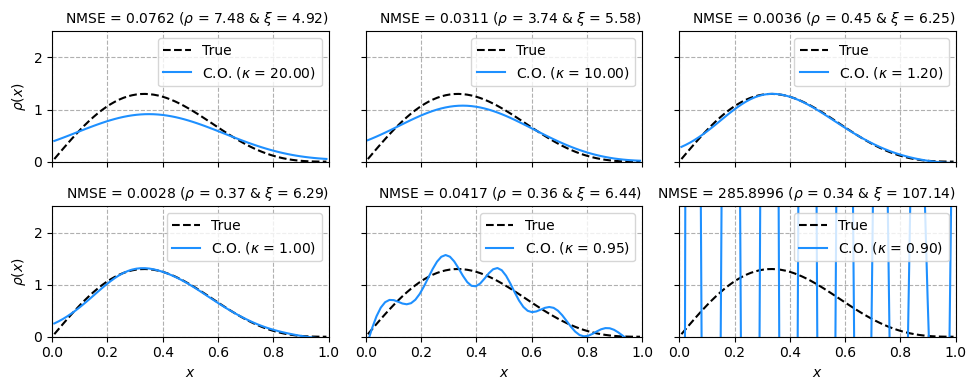

In [15]:
fig, axs = plt.subplots(2, 3, figsize = (10,4), sharex=True, sharey=True)
j = 0
for row in np.arange(2):
    for col in np.arange(3):
        axs[row,col].plot(x, rhox, '--k', label = 'True')
        axs[row,col].plot(x, rhox_st[j], color = 'dodgerblue', label = r'C.O. ($\kappa$ = {0:.2f})'.format(factors[j]))
        axs[row,col].set_title(r'NMSE = {} ($r$ = {} & $s$ = {})'.format(np.round(nmse[j], 4), np.round(res_norm[j],2), 
                                                                         np.round(sol_norm[j],2)), loc = 'right', fontsize=10)

        axs[row,col].set_xlim((0, 1))
        axs[row,col].set_ylim((0, 2.5)); 
        axs[row,col].grid(linestyle = '--')
        axs[row,col].legend(loc = 'upper right')
        j += 1
        axs[1,col].set_xlabel(r'$x$')
    axs[row,0].set_ylabel(r'$\rho(x)$')
plt.tight_layout()

### Pergunta: O que você observa sobre $r$, $s$ e o NMSE à medida que $k$ diminui? 
<details>
  <summary><b>▶ Clique aqui para ver a resposta</b></summary>
  
  <br>
  
  ### Resposta
- à medida que $k$ diminui (nossa margem acima do ruído), o NMSE diminui em princípio. O efeito parece estabilizar quando $k \rightarrow 1$; quando $k$ cai abaixo de $1.0$, o NMSE volta a aumentar e cresce abruptamente. O motivo é que estamos forçando o otimizador a achar a solução dentro do nível do ruído. Numericamente, o otimizador vai falhar se $k$ diminiur de mais.
- à medida que $k$ diminui, a norma do resíduo ($r$) diminui. Surpreendentemente, mesmo para $k<1.0$, isto é verdade. Isto é *overfitting* ou a uma solução sub-regularizada;
- note que a norma da solução, $s$, aumenta à medida que $k$ diminui. Quando $k<1.0$, ela tende a se tornar excessivamente grande. O *overfitting* significa que seu otimizador aprendeu mais sobre o ruído do que sobre o termo fonte;
- note também que $s$ torna-se bastante pequeno à medida que $k$ aumenta. isto corresponde à *underfitting* ou a uma solução sobre-regularizada. Neste caso, o otimizador foi orientado a ficar tão longe do ruído, que acaba suprimindo componentes úteis do termo fonte. A consequência é uma solução que tende a ser sobre-suavizada. 
</details> 

### Pergunta: Será que é fácil medir o ruído? Dá pra desligar a fonte e medir o ruído sem ela? 
<details>
  <summary><b>▶ Clique aqui para ver a resposta</b></summary>
  
  <br>
  
  ### Resposta
- Há situações em que é impossível desligar a fonte e medir apenas o ruído (*e.g.* o problema da gravidade)
- Em alguns casos, isto é possível e apenas adiciona uma complicação ao processo (*e.g.*, numa medição acústica, você pode desligar o alto-falante e deixar o microfone gravar o ruído ambiente).
</details> 

## B. SVD Truncado (*Truncated* SVD - TSVD)

Vamos voltar ao SVD e nos lembrar da solução aproximada escrita na forma da Eq. (6)

\begin{equation}
\hat{\textbf{x}}_k = \sum\limits_{i=1}^{L}\varphi_i\frac{\textbf{u}_{i}^{H}\textbf{b}}{\sigma_i} \textbf{v}_{i}
\end{equation}

A análise com o plot de Picard deixa evidente que os erros extremamente grandes na solução ingênua provêm dos **componentes ruidosos da SVD**, associados aos menores valores singulares e às maiores frequências espaciais. A boa notícia é que nossa análise indica que uma parte dos valores singulares é confiável. Particularmente, os componentes para os quais $|\textbf{u}_{i}^{H}\textbf{b}| / \sigma_i \approx |\textbf{u}_{i}^{H}\textbf{b}_{\text{exa}}| / \sigma_i$ (claro, isso é válido se o valor exato da solução satisfizer o critério de Picard - o que é bastante razoável).

Estas considerações conduzem imediatamente a um método para calcular soluções aproximadas regularizadas: basta **eliminar** (ou zerar) os componentes do SVD dominados pelo ruído. Assim, definimos a solução SVD truncada (**TSVD** - *Truncated Singular Value Decomposition*), $\hat{\textbf{x}}_k$, como a solução obtida mantendo os primeiros $k$ componentes da solução ingénua, de modo que

\begin{equation}
    \varphi_{i}^{[k]} = 
    \begin{cases}
      1 \ \ \ \ \ \ \ 1 \leq i \leq k  \\
      0 \ \ \ \ \ \ \ k < i \leq L
    \end{cases}
\tag{8}
\end{equation}

A escolha do valor de $k$ pode ser feita com base na **inspeção visual** do plot de Picard (portanto, não é muito automática).

In [16]:
ks = [2, 4, 6, 8, 10, 12, 14, 16 , 18]
rhox_k = []
nmse = []
sol_norm = []
res_norm = []
for k in ks:
    xk = lc.tsvd(U, s, V, gxln, k)
    rhox_k.append(xk)
    nmse.append(lc.nmse(xk, rhox))
    sol_norm.append(np.linalg.norm(xk))
    res_norm.append(np.linalg.norm(A@xk-gxln))

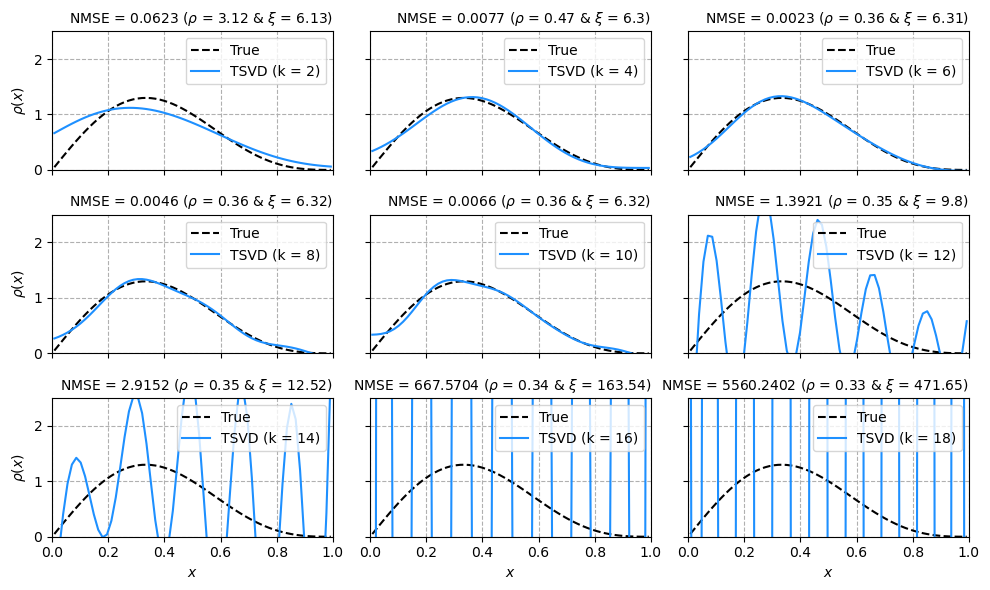

In [17]:
fig, axs = plt.subplots(3, 3, figsize = (10,6), sharex=True, sharey=True)
j = 0
for row in np.arange(3):
    for col in np.arange(3):
        axs[row,col].plot(x, rhox, '--k', label = 'True')
        axs[row,col].plot(x, rhox_k[j], color = 'dodgerblue', label = r'TSVD (k = {})'.format(ks[j]))
        axs[row,col].set_title(r'NMSE = {} ($r$ = {} & $s$ = {})'.format(np.round(nmse[j], 4), np.round(res_norm[j],2), 
                                                                         np.round(sol_norm[j],2)), loc = 'right', fontsize=10)
        axs[row,col].set_xlim((0, 1))
        axs[row,col].set_ylim((0, 2.5)); 
        axs[row,col].grid(linestyle = '--')
        axs[row,col].legend(loc = 'upper right')
        j += 1
        axs[2,col].set_xlabel(r'$x$')
    axs[row,0].set_ylabel(r'$\rho(x)$')
plt.tight_layout()

### Pergunta: O que você observa sobre $r$, $s$ e o NMSE à medida que $k$ aumenta? 
<details>
  <summary><b>▶ Clique aqui para ver a resposta</b></summary>
  
  <br>
  
  ### Resposta
- à medida que $k$ aumenta (número de componentes do SVD), o NMSE diminui em princípio (até $k=8)$. Passado um certo ponto, a inclusão de mais componentes de SVD se torna prejudicial e o NMSE aumenta consideravelmente. Olhe o plot de Picard e preste atenção aos detalhes. o motivo para o aumento do NMSE é a inclusão de mais e mais componentes ruidosos do SVD.
- à medida que $k$ aumenta, a norma do resíduo ($r$) diminui. Surpreendentemente, mesmo para $k>8$, isto é verdade. Isto é *overfitting* ou uma solução sub-regularizada;
- note que a norma da solução, $s$, aumenta à medida que $k$ aumenta. Quando $k>8$, ela tende a se tornar excessivamente grande. O *overfitting* significa que o TSVD incluiu mais informação sobre o ruído do que sobre o termo fonte na solução;
- note também que $s$ tende a ser pequeno para $k<8$ aumenta. Isto corresponde à *underfitting* ou a uma solução sobre-regularizada. Neste caso, alguns dos componentes úteis (associados ao valor exato da solução) acabam suprimidos. A consequência é uma solução que tende a ser sobre-suavizada. 
</details> 

# C. Regularização de Tikhonov

A vantagem do método **TSVD** é ser intuitivo e fácil de calcular as soluções, $\hat{\mathbf{x}}_k$, para diferentes valores de $k$. A desvantagem é que se trata de um método de força bruta, no qual os parâmetros de filtragem, $\varphi_i$, são truncados abruptamente.

Provavelmente, o método de regularização mais bem-sucedido de todos os tempos é a regularização de Tikhonov. Este método provavelmente foi inventado várias vezes, mas o nome de Tikhonov (<a href="https://mathshistory.st-andrews.ac.uk/Biographies/Tikhonov/" target="_blank">Bio</a>) está corretamente associado a ele. De forma semelhante à formulação da TSVD, o método de Tikhonov incorpora explicitamente o requisito de regularidade no enunciado do problema, sendo definida como a seguinte solução do problema de otimização

\begin{equation}
\hat{\textbf{x}}_{\lambda} = \text{min}(\left\|\textbf{Ax-b}\right\|^{2}_{2} + \lambda^2\left\|\textbf{x}\right\|^{2}_{2}).
\tag{9}
\end{equation}
em que $\lambda>0$ é o parâmetro de regularização, que controla os pesos dos dois ingredientes na minimização, a saber

- **norma do resíduo** $\rho = \left\|\textbf{Ax-b}\right\|^{2}_{2}$, que mede a qualidade do ajuste. Obviamente, se este termo for demasiado grande, então $\hat{\textbf{x}}_{\lambda}$ não pode ser considerado uma boa solução, pois não "resolve o problema". Por outro lado, intuitivamente, não devemos tornar o resíduo menor do que a dimensão média dos erros em $\textbf{b}$; à semelhança dos problemas de ajuste de dados, não queremos ajustar nosso modelo ao ruído presente nos dados (**overfitting**).

- **norma da solução** $\xi = \left\|\textbf{x}\right\|^{2}_{2}$, que mede a regularidade da solução. A incorporação deste termo baseia-se no nosso conhecimento de que a solução ingênua é dominada por componentes de alta frequência, com grandes amplitudes (amplificadas). A esperança é, portanto, que se controlarmos a norma de $\textbf{x}$, podemos suprimir a maioria dos componentes ruidosos.

#### O caminho de regularização na solução de Tikhonov

<div style="background-color: #f0f2f5; padding: 15px; text-align: justify; border-radius: 8px; margin: 0 auto; max-width: 1100px;">
O equilíbrio entre os dois termos é controlado pelo fator $\lambda^2$ (ou $\lambda$ em alguns livros). Quanto maior o $\lambda$, maior o peso dado à minimização da norma da solução, $\left\|\textbf{x}\right\|^{2}_{2}$, e, portanto, mais regularizada será a solução. Notamos que $\left\|\textbf{x}\right\|^{2}_{2}\rightarrow 0$ à medida que $\lambda \rightarrow \infty$. Por outro lado, quanto menor for $\lambda$, maior o peso dado ao ajuste aos dados ruidosos, resultando em soluções menos regularizadas (obtemos a solução por mínimos quadrados quando $\lambda = 0$).
</div>

### Solução analítica

Pode-se demonstrar que a solução de Tikhonov tem solução analítica do seguinte problema de mínimos quadrados

\begin{gather}
\hat{\textbf{x}}_{\lambda} = \text{min}\left(\left\|
  \begin{bmatrix}
   \textbf{A} \\ \lambda \textbf{I} 
   \end{bmatrix}
   - 
   \begin{bmatrix}
   \textbf{b} \\ \textbf{0} 
   \end{bmatrix}
   \right\|_{2}\right)
\end{gather}
com solucão dada por:

\begin{equation}
\hat{\textbf{x}}_{\lambda} = (\textbf{A}^H\textbf{A}+\lambda^2\textbf{I})^{-1}\textbf{A}^H \textbf{b}
\tag{10}
\end{equation}

**NOTE**: o SVD mantém as dimensões originais de $\textbf{A}$, enquanto $\textbf{A}^H\textbf{A}$ [$(L \times M) \times (M \times L$)] pode ter uma dimensão bem maior e, portanto, ter um número de condição ainda pior que o do problema original.

Podemos usar a expansão de $\textbf{A}= \textbf{U} \Sigma \textbf{V}^H$ e sua pseudo-inversa e lembrar que $\textbf{V}^H\textbf{V} = \textbf{I}$. Dessa forma, obtemos

\begin{equation}
\hat{\textbf{x}}_{\lambda} = \textbf{V}(\Sigma^2+\lambda^2\textbf{I})^{-1} \ \Sigma \textbf{U}^H \textbf{b}
\tag{11}
\end{equation}

que comparado à

\begin{equation}
\hat{\textbf{x}}_{\lambda} = \sum\limits_{i=1}^{L}\varphi_{i}^{[\lambda]}\frac{\textbf{u}_{i}^{H}\textbf{b}}{\sigma_i} \textbf{v}_{i}
\tag{12}
\end{equation}
nos permite inferir que os **fatores de filtragem** são

\begin{equation}
    \varphi_{i}^{[\lambda]} = \frac{\sigma_{i}^{2}}{\sigma_{i}^{2}+\lambda^2} \approx
    \begin{cases}
      1 \ \ \ \ \ \ \ \ \ \ \ \ \ \ \lambda \ll \sigma_i \\
      \sigma_{i}^{2}/\lambda^2 \ \ \ \ \ \ \ \lambda \gg \sigma_i
    \end{cases}
\tag{13}
\end{equation}

Observemos o que ocorre quando usamos diferentes valores em $\lambda$.

In [20]:
lambdas = [10, 2.5, 0.7, 0.2, 0.05, 0.015, 0.01, 0.0015 , 0.0005]
rhox_lam = []
nmse = []
sol_norm = []
res_norm = []
for lam in lambdas:
    xlam = lc.tikhonov(U, s, V, gxln, lam)
    sol_norm.append(np.linalg.norm(xlam))
    rhox_lam.append(xlam)
    nmse.append(lc.nmse(xlam, rhox))
    sol_norm.append(np.linalg.norm(xlam))
    res_norm.append(np.linalg.norm(A@xlam-gxln))

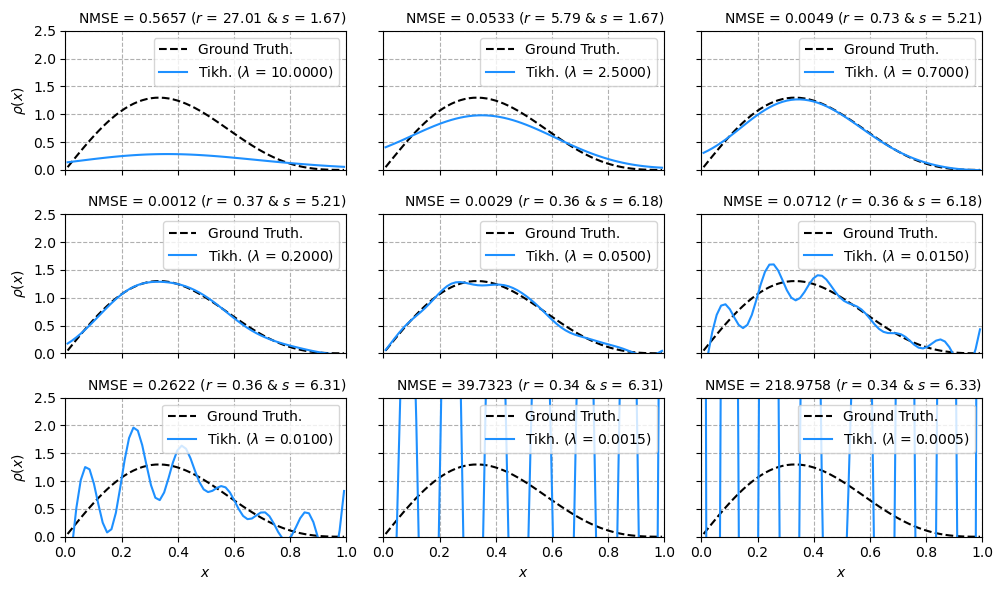

In [21]:
fig, axs = plt.subplots(3, 3, figsize = (10,6), sharex=True, sharey=True)
j = 0
for row in np.arange(3):
    for col in np.arange(3):
        axs[row,col].plot(x, rhox, '--k', label = 'Ground Truth.')
        axs[row,col].plot(x, rhox_lam[j], color = 'dodgerblue', label = r'Tikh. ($\lambda$ = {0:.4f})'.format(lambdas[j]))
        axs[row,col].set_title(r'NMSE = {} ($r$ = {} & $s$ = {})'.format(np.round(nmse[j], 4), np.round(res_norm[j],2), 
                                                                         np.round(sol_norm[j],2)), loc = 'right', fontsize=10)
        axs[row,col].set_xlim((0, 1))
        axs[row,col].set_ylim((0, 2.5)); 
        axs[row,col].grid(linestyle = '--')
        axs[row,col].legend(loc = 'upper right')
        j += 1
        axs[2,col].set_xlabel(r'$x$')
    axs[row,0].set_ylabel(r'$\rho(x)$')
plt.tight_layout()

### Pergunta: O que você observa sobre $r$, $s$ e o NMSE à medida que $\lambda$ diminui? 
<details>
  <summary><b>▶ Clique aqui para ver a resposta</b></summary>
  
  <br>
  
  ### Resposta
- à medida que $\lambda$ diminui, o NMSE diminui em princípio ($\lambda = 0.2$). Para $\lambda < 0.2$, o NMSE aumenta consideravelmente. 
- à medida que $\lambda$ diminui, a norma do resíduo ($r$) diminui. Surpreendentemente, mesmo para $\lambda<0.2$, isto é verdade. Isto é *overfitting* ou uma solução sub-regularizada;
- note que a norma da solução, $s$, aumenta em princípio ($10 < \lambda < 0.2$). Quando $\lambda < 0.2$, ela tende a aumentar até se tornar excessivamente grande para valores muito pequenos (casos em que a solução de Tikhonov se parecerá mais e mais a de mínimos quadrados, que tende a possuir *overfitting*;
- note também que $s$ tende a diminuir para $\lambda > 0.2$. Isto corresponde à *underfitting* ou a uma solução sobre-regularizada. Neste caso, alguns dos componentes úteis (associados ao valor exato da solução) acabam suprimidos. A consequência é uma solução que tende a ser sobre-suavizada. 
</details> 

### O efeito da filtragem no plot de Picard

Vejamos o efeito da solução de Tikhonov no plot de Picard. Primeiro, antes de aplicar a filtragem.

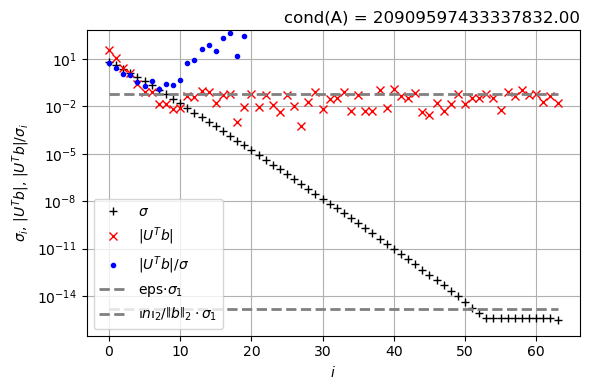

In [22]:
lc.plot_picard(U, s, gxln, noise_norm = np.linalg.norm(n), figsize = (6,4))

Value of $\lambda$: 0.2000


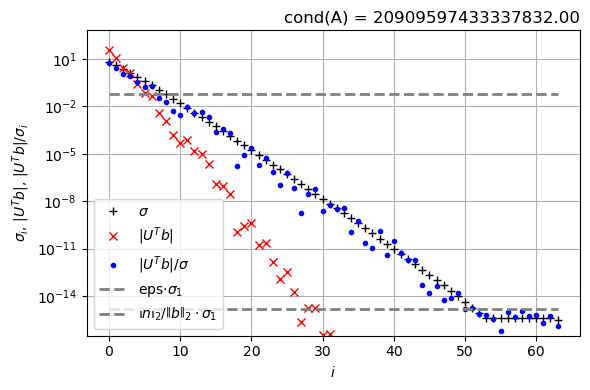

In [23]:
labda_val = lambdas[3]
print(r"Value of $\lambda$: {:.4f}".format(labda_val))
phi_lam = s**2/(s**2+labda_val**2)
lc.plot_picard(U*phi_lam, s, gxln, noise_norm = np.linalg.norm(n), figsize = (6,4))

## Retomando:

\begin{equation}
\hat{\textbf{x}}_{\lambda} = \sum\limits_{i=1}^{L}\varphi_{i}^{[\lambda]}\frac{\textbf{u}_{i}^{H}\textbf{b}}{\sigma_i} \textbf{v}_{i}
\end{equation}
com os **fatores de filtragem** sendo

\begin{equation}
    \varphi_{i}^{[\lambda]} = \frac{\sigma_{i}^{2}}{\sigma_{i}^{2}+\lambda^2} \approx
    \begin{cases}
      1 \ \ \ \ \ \ \ \ \ \ \ \ \ \ \lambda \ll \sigma_i \\
      \sigma_{i}^{2}/\lambda^2 \ \ \ \ \ \ \ \lambda \gg \sigma_i
    \end{cases}
\end{equation}

- Vemos que para valores singulares $\lambda \ll \sigma_i$, os fatores de filtragem $\varphi_{i}^{[\lambda]} \approx 1.0$ e os componentes da SVD correspondentes contribuem para $\hat{\textbf{x}}_{\lambda}$ com força quase total. 

- Por outro lado, para $\lambda \gg \sigma_i$, os fatores de filtragem são pequenos e, portanto, os valores singulares tornam-se cada vez mais amortecidos ou filtrados à medida que $\sigma$ diminui. Notamos que, neste último caso, os fatores de filtragem $\varphi_{i}^{[\lambda]}$ são proporcionais a $\sigma_{i}^{2}$, e, portanto, decaem suficientemente rápido para diminuir a influência dos fatores crescentes $\frac{\textbf{u}_{i}^{H}\textbf{b}}{\sigma_i} \approx \frac{\textbf{u}_{i}^{H}\textbf{n}}{\sigma_i}$.

A transição entre os componentes de SVD retidos e filtrados é mais suave do que no TSVD.

## Observe o valor de $\varphi_{i}^{[\lambda]}$ vs. $\sigma_i$

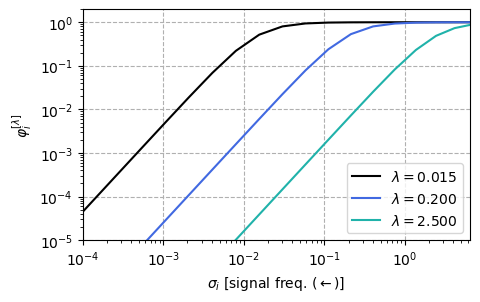

In [38]:
labda_val_1 = lambdas[5]
labda_val_2 = lambdas[3]
labda_val_3 = lambdas[1]

# Filters
phi_lam_1 = s**2/(s**2+labda_val_1**2)
phi_lam_2 = s**2/(s**2+labda_val_2**2)
phi_lam_3 = s**2/(s**2+labda_val_3**2)


plt.figure(figsize = (5,3))
plt.loglog(s, phi_lam_1, 'k', label = '$\lambda = ${:.3f}'.format(labda_val_1))
plt.loglog(s, phi_lam_2, 'royalblue', label = '$\lambda = ${:.3f}'.format(labda_val_2))
plt.loglog(s, phi_lam_3, 'lightseagreen', label = '$\lambda = ${:.3f}'.format(labda_val_3))
plt.legend()
plt.xlabel(r'$\sigma_i$ [signal freq. ($\leftarrow$)]')
plt.ylabel(r'$\varphi_{i}^{[\lambda]}$')
plt.xlim((1e-4, s[0]))
plt.ylim((1e-5, 2))
plt.grid(linestyle = '--')

# 3 . A curva L (L-curve)

Nossa análise dos três métodos de regularização revelou que:

- soluções **sub-regularizadas** ($\lambda$ pequeno - Tikhonov, $k$ grande - TSVD) tendem a possuir uma norma de solução, $\left\|\mathbf{x}\right\|_2$, muito grande e uma norma de resíduo,  $\left\|\mathbf{Ax-b}\right\|_2$ , pequena (*overfitting*);
- soluções **sobre-regularizadas** ($\lambda$ grande - Tikhonov, $k$ pequeno - TSVD) tendem a possuir uma norma de solução, $\left\|\mathbf{x}\right\|_2$, muito pequena e uma norma de resíduo,  $\left\|\mathbf{Ax-b}\right\|_2$ , grande (*underfitting*);

A questão que fica é: **Será que podemos buscar um ponto ótimo?**

Até aqui, avaliamos apenas alguns valores de $\lambda$ ou de $k$. Analisemos mais de perto a **norma da solução** ($\left\|\mathbf{x}\right\|_{2}$) e a **norma do resíduo** ($\left\|\mathbf{Ax-b}\right\|_{2}$). Elas desempenham um papel central no tratamento prático de problemas discretos mal postos, porque podem sempre ser calculadas independentemente do método de regularização utilizado; não requerem o cálculo da SVD (necessariamente) ou de qualquer outra decomposição matricial. Vamos plotar a curva $\left\|\mathbf{x}\right\|_{2}$ vs. $\left\|\mathbf{Ax-b}\right\|_{2}$ para vários valores de $\lambda$ e ver o que acontece em escala log-log.

In [210]:
# Several lambda values
lambdas = np.logspace(-5, 1, num=100) # logspace from 0.00001 to 10
# Solution and residual norms init
sol_norms = np.zeros(len(lambdas))
residuals = np.zeros(len(lambdas))
# loop
for jl, lam in enumerate(lambdas):
    xlam = lc.tikhonov(U, s, V, gxln, lam)
    sol_norms[jl] = np.linalg.norm(xlam)
    residuals[jl] = np.linalg.norm(A @ xlam - gxln)

chosen_indexes = [33, 41, 55, 75, 85, 95]

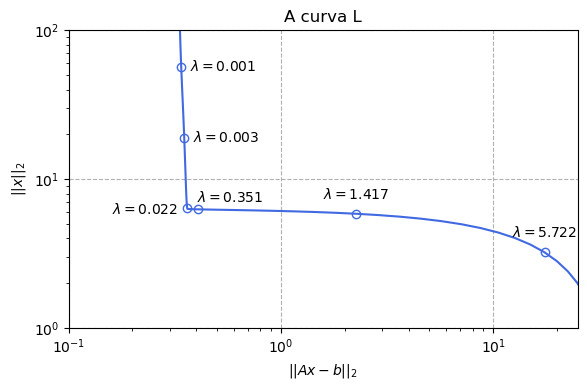

In [178]:
plt.figure(figsize = (6,4))
plt.loglog(residuals, sol_norms, color = 'Royalblue')
plt.loglog(residuals[chosen_indexes], sol_norms[chosen_indexes],  'o', color = 'Royalblue', markerfacecolor='none')
for num in chosen_indexes[:2]:
    label = r"$\lambda = ${:.3f}".format(lambdas[num])
    plt.annotate(label, (residuals[num], sol_norms[num]), textcoords="offset points", xytext=(30, -3), ha='center') 
for num in chosen_indexes[2:3]:
    label = r"$\lambda = ${:.3f}".format(lambdas[num])
    plt.annotate(label, (residuals[num], sol_norms[num]), textcoords="offset points", xytext=(-30, -4), ha='center')
for num in chosen_indexes[3:4]:
    label = r"$\lambda = ${:.3f}".format(lambdas[num])
    plt.annotate(label, (residuals[num], sol_norms[num]), textcoords="offset points", xytext=(23, 5), ha='center')
for num in chosen_indexes[4:6]:
    label = r"$\lambda = ${:.3f}".format(lambdas[num])
    plt.annotate(label, (residuals[num], sol_norms[num]), textcoords="offset points", xytext=(0, 11), ha='center') 
plt.grid(linestyle = '--')
plt.ylim((1, 100))
plt.xlim((0.1, 25))
plt.xlabel(r'$||A x - b||_2$')
plt.ylabel(r'$||x||_2$')
plt.title("A curva L")
plt.tight_layout();

### O que você nota? 
<details>
  <summary><b>▶ Clique aqui para ver a resposta</b></summary>
  
  <br>
  
  ### Resposta
- A curva apresenta um comportamento típico, comum em muitas situações (um "L").

- Quando $\lambda$ é grande demais, a solução $\hat{\mathbf{x}}_{\lambda}$ é sobre-regularizada, com sua norma penalizada excessivamente no processo de minimização. Este é um caso de **under-fitting** do ajuste do modelo aos dados medidos.

- Quando $\lambda$ é pequeno demais, a solução $\hat{\mathbf{x}}_{\lambda}$ é subsuavizada, pois a norma da solução é pouco penalizada na minimização. Este é um caso de **overfitting** do modelo aos dados medidos - o modelo se ajusta ao ruído.

</details> 

### E em que local da curva L você acha que a solução ótima se encontra? 
<details>
  <summary><b>▶ Clique aqui para ver a resposta</b></summary>
  
  <br>
  
  ### Resposta
- Na quina;
- Ou no ponto em que temos um balanço entre $\left\|\hat{\mathbf{x}}\right\|_2$ e $\left\|\hat{\mathbf{Ax-b}}\right\|_2$ serem pequenos.
- Após a quina ($\lambda \rightarrow \infty$), $\left\|\hat{\mathbf{x}}\right\|_2$ não decai muito mais e $\left\|\hat{\mathbf{Ax-b}}\right\|_2$ tende a aumentar (*under-fitting*);
- Por outro lado, antes da quina ($\lambda \rightarrow \infty$),  $\left\|\hat{\mathbf{x}}\right\|_2$ tende a aumentar muito e $\left\|\hat{\mathbf{Ax-b}}\right\|_2$ tende ao seu valor mínimo (*over-fitting*)
- Tecnicamente, a quina é o ponto de maior curvatura da curva L.
</details> 

## Será que podemos usar algum algorítmo pra automatizar a busca pelo valor ótimo de $\lambda$?

- A boa notícia é que **sim** e que há mais de um método. Veremos estes métodos na sequência. Veja só na prática.

Optimal regularization parameter by L-curve: 0.05812265685400434


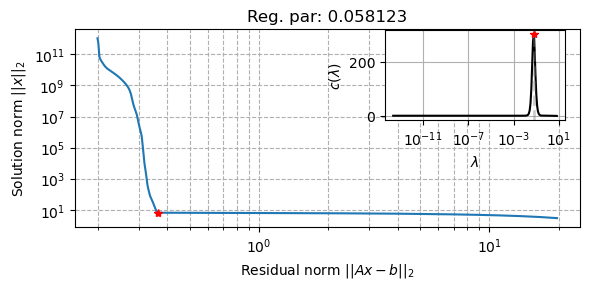

In [159]:
lam_opt = lc.l_curve(U, s, gxln, plotit = True)
print("Optimal regularization parameter by L-curve: {}".format(lam_opt[0]))

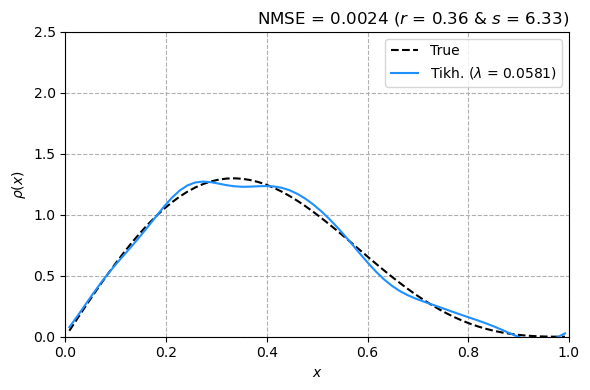

In [171]:
# solution
x_opt = lc.tikhonov(U, s, V, gxln, lam_opt)
# metrics
nmse = lc.nmse(x_opt, rhox)
res_norm = np.linalg.norm(A@x_opt-gxln)
sol_norm = np.linalg.norm(x_opt)
# Fig
plt.figure(figsize = (6,4))
plt.plot(x, rhox, '--k', label = 'True')
plt.plot(x, x_opt, color = 'dodgerblue', label = r'Tikh. ($\lambda$ = {0:.4f})'.format(lam_opt[0]))
plt.title(r'NMSE = {} ($r$ = {} & $s$ = {})'.format(np.round(nmse, 4), np.round(res_norm,2), np.round(sol_norm,2)), loc = 'right', fontsize=12)
plt.xlim((0, 1))
plt.ylim((0, 2.5)); 
plt.grid(linestyle = '--')
plt.legend(loc = 'upper right')
plt.xlabel(r'$x$')
plt.ylabel(r'$\rho(x)$')
plt.tight_layout()

# 4. Reconstrução

Até aqui, nos preocupamos apenas com a ideia de encontrar uma solução sensata para um problema complexo. Mas pense por um instante: quanto poder isso nos dá? Ora, se você computou uma boa aproximação da causa do problema, talvez você possa inferir algo sobre o fenômeno em questão em locais onde você não mediu. Desejamos **reconstruir** uma quantidade desejada em pontos não observados da variável independente.

Por exemplo, no problema da gravidade, medimos a aceleração da gravidade, $g(x')$, a uma distância $d$ [m] e inferimos o termo-fonte, $\rho(x)$. Seria útil, no entanto, reconstruir a aceleração da gravidade para valores $d$ menores ou maiores que o medido. Vamos reconstruir a aceleração da gravidade onde não a observamos diretamente. 

Note que:

- $d = 0$ m representa uma origem hipotética para o campo de densidades. É o nosso termo fonte e, usualmente, não conseguimos reconstruir nada para $d \leq 0$ (nossa área de reconstrução não deve **conter fontes**);
- Mas podemos reconstruir $g(x')$ para outros valores de $d$ (mais perto ou mais longe do plano de medição).

A reconstrução é um **problema direto** (*forward problem*). Note que já computamos $\textbf{x}$ pelo problema inverso regularizado. Precisamos então computar

\begin{equation}
\textbf{b}_{\text{r}} = \textbf{A}_{\text{r}} \hat{\textbf{x}}
\tag{14}
\end{equation}
em que $\textbf{A}_{\text{r}}$ é a matriz de reconstrução avaliada nas posições de reconstrução desejadas.

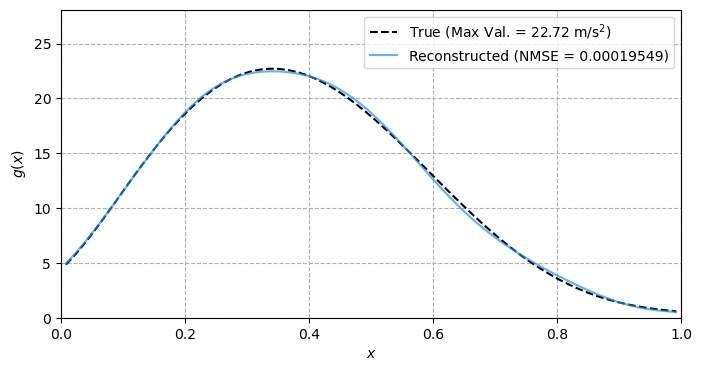

In [177]:
# distancia de reconstrução desejada
dr = 0.1

# Matriz de reconstrução
Ar, xr = tp.gravity_model(n = order,a = a, b = b,d = dr)

# Ground Truth
gxt = Ar @ rhox
# reconstruido
gxr = Ar @ x_opt

nmse = lc.nmse(gxt, gxr)

############ Figure ###########################
plt.figure(figsize = (8,4))
plt.plot(x, gxt, '--k', label = 'True (Max Val. = {:.2f} m/s$^2$)'.format(np.amax(gxt)))
plt.plot(x, gxr, 'dodgerblue', label = r'Reconstructed (NMSE = {:.8f})'.format(nmse), alpha = 0.7)
plt.legend()
plt.grid(linestyle = '--')
plt.ylim((0,1.25*np.amax(gxr)))
plt.xlim((0,1))
plt.xlabel(r'$x$')
plt.ylabel(r'$g(x)$');

### O que você nota à media que a distância de reconstrução se aproxima ou se afasta da fonte? Por que? 
<details>
  <summary><b>▶ Clique aqui para ver a resposta</b></summary>
  
  <br>
  
  ### Resposta
- Quando a distância de reconstrução se afasta da fonte, o erro de reconstrução (NMSE) tende a diminiuir. Isso ocorre porque as componentes de alta frequência terão decaído e a filtragem feita pela regularização faz um excelente trabalho de reconstrução;
- Quando a distância de reconstrução se aproxima da fonte, o erro de reconstrução (NMSE) tende a aumentar. Agora estamos amplificando as componentes de alta frequência, que foram corrompidas por ruído. A filtragem feita pela regularização ainda pode fazer um bom trabalho, mas é preciso tomar mais cuidado na análise.

</details> 

# Exercícios

### 1. Refaça as análises do caminho de regularização para a otimização com restrição, TSVD e regularização de Tikhonov para os seguintes problemas:

**(a). O problema da gravidade:** variando: (a) o nível de ruído; (b) usando o termo-fonte "density_pieciwise" (o termo com descontinuidade). Note o quão difícil é encontrar soluções sensatas para um termo-fonte com descontinuidades. Pense nisso do ponto de vista da presença de termos de alta frequência no sinal do termo-fonte.

**(b). O problema do calor na barra:** considerando diferentes níveis de ruído e diferentes termos-fonte.

### 2. O plot da curva L
Refaça o plot da curva L feita durante a aula. Tente mudar a escala para linear (nas abscissas e nas ordenadas). Tente dar um zoom na curva no entorno da quina. Adicione uma linha horizontal para a norma da solução do valor verdadeiro do termo fonte e outra vertical para a norma do ruído. O que você observa? Ache, por tentativa e erro, um valor de $\lambda$ que minimize a norma $\left\|\mathbf{x}_{\text{exact}}-\mathbf{x}_{\lambda}\right\|$. Adicione o ponto $(\left\|\mathbf{x}_{\lambda}\right\|, \left\|\mathbf{A}\mathbf{x}_{\lambda}-\mathbf{b}\right\|)$ à sua curva L. Será que ele está próximo da quina?